In [8]:
from qutip import *
import numpy as np
import matplotlib.pyplot as plt

N_cav = 30 #(truncado)
N_atomos = 5
epsilon = .3
lamda = 1
g = lamda / 2*(np.sqrt(N_atomos)) # Acoplamiento

tiempo = 30
pasos = 200
a = tensor([destroy(N_cav)] + [qeye(2) for _ in range(0,  N_atomos)])

#Definimos a la lista de los operadores individuales:
sigmaz_list = [tensor([qeye(N_cav)] + [sigmaz() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmam_list = [tensor([qeye(N_cav)] + [sigmam() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmap_list = [tensor([qeye(N_cav)] + [sigmap() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]

#Ahora definimos a los operadores colectivos
J_z = sum(sigmaz_list)
J_m = sum(sigmam_list)
J_p = J_m.dag()

In [9]:
tlist = np.linspace(0, tiempo, pasos)

estado_inicial = tensor([basis(N_cav, 1)] + [basis(2,0) for _ in range(N_atomos)])
rho0 = ket2dm(estado_inicial)

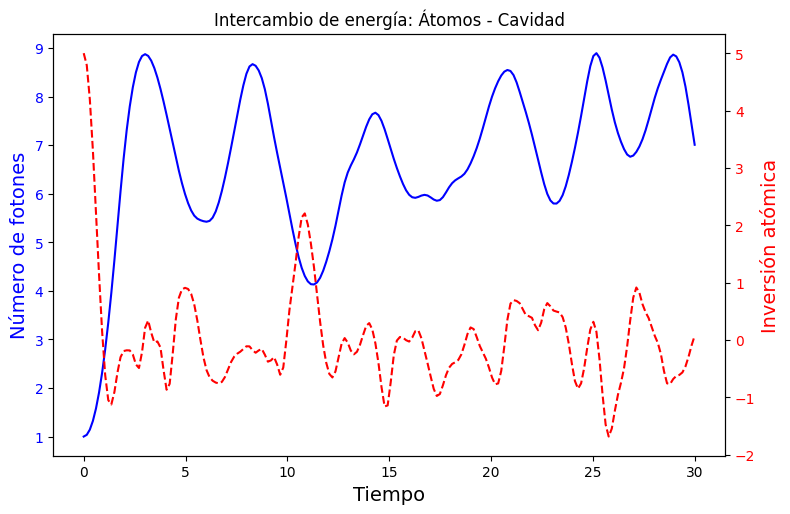

: 

In [ ]:
H = a.dag() * a + (epsilon/2) * J_z + (g/2) * (a  + a.dag()) * (J_p + J_m)
result = mesolve(H, rho0, tlist, c_ops=[], e_ops=[a.dag() * a, J_z], options={"store_states": True})
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()